# Modelado y evaluación
**Proyecto:** ¿Qué tan pronto se podría saber quién llega a los playoffs de la NFL?
**Alumno:** Tomás Roa Gunn  |  **Materia:** Aprendizaje Automático, Centro Politécnico Superior Malvinas Argentinas

Este notebook entrenaría y compararía **regresión logística, árbol de decisión, KNN y SVM** para cada corte de la temporada (4, 6, 9 y 12 partidos), junto con dos referencias simples. Los números del README y del resto de la documentación saldrían de **una única ejecución** de este notebook (carpeta `reports/`).

**Reglas de la evaluación (fijadas antes de ejecutar nada)**
- **Unidad de análisis:** una fila sería un equipo en una temporada, con sus variables calculadas hasta su partido N.
- **Momento de la predicción:** después del partido N de cada equipo (entre la semana N y la N+1, por la semana de descanso).
- **Evaluación retrospectiva *walk-forward*:** para cada temporada `y` entre 2010 y 2025 se entrenaría con 2002 hasta `y-1` y se evaluaría en `y`, **una sola vez**. Las temporadas 2019 a 2025 ya se habían usado como prueba en la Semana 6, por lo que se reportarían aparte.
- **Hiperparámetros:** se elegirían **solo con el entrenamiento**, con validación interna por **temporadas completas** (nunca se parte una temporada).
- **Escalado:** dentro de un `Pipeline`, ajustado solo con el entrenamiento de cada partición (KNN, SVM y logística lo usan, el árbol no lo necesita).
- **Criterio de "predicción confiable":** definido en la sección 2, antes de ver resultados.

In [1]:
import sys
sys.path.append("..")
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import Markdown, display
from sklearn.tree import export_text

from nfl_playoffs.config import CORTES, FIGURAS, PREDICTORES, PROCESSED, RAW, OBJETIVO, MODELOS_DIR, REPORTES
from nfl_playoffs.features import cargar_partidos, partidos_por_equipo, variables_corte
from nfl_playoffs.modelado import (CRITERIO, ajustar_final, aplicar_criterio, evaluar_corte, buscar, modelos, predecir, resumir)
from nfl_playoffs.validacion import tramos_walk_forward

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
FIGURAS.mkdir(parents=True, exist_ok=True); REPORTES.mkdir(parents=True, exist_ok=True); MODELOS_DIR.mkdir(parents=True, exist_ok=True)
NOMBRES = {"siempre_no_llega": "Siempre «no llega»", "regla_pct_victorias": "Regla por % de victorias", "logistica": "Regresión logística",
           "logistica_umbral": "Logística con umbral", "arbol": "Árbol de decisión", "knn": "KNN", "svm": "SVM (RBF)"}
R = {}  # resultados que luego se usan en reports/resultados.md y README

## 1. Datos y predictores
Se leerían los archivos de `data/processed/` generados por `python -m nfl_playoffs.dataset` (ver `notebooks/1.0-...`). Cada corte tiene 768 filas (32 equipos por 24 temporadas, 2002 a 2025). La **etiqueta** `llega_playoffs` vale 1 si el equipo jugó al menos un partido `WC`, `DIV`, `CON` o `SB` en esa temporada.

In [2]:
tablas = {n: pd.read_csv(PROCESSED / f"variables_corte_{n:02d}.csv") for n in CORTES}
for n, t in tablas.items():
    assert (t.partidos == n).all() and t.isna().sum().sum() == 0
pred = pd.DataFrame({f"corte {n}": pd.Series(v) for n, v in PREDICTORES.items()})
print("Filas por corte:", {n: len(t) for n, t in tablas.items()}, "| positivos:", f"{tablas[9].llega_playoffs.mean():.1%}")
pred

Filas por corte: {4: 768, 6: 768, 9: 768, 12: 768} | positivos: 39.1%


,corte 4,corte 6,corte 9,corte 12
0,pct_victorias,pct_victorias,pct_victorias,pct_victorias
1,puntos_favor_prom,puntos_favor_prom,puntos_favor_prom,puntos_favor_prom
2,puntos_contra_prom,puntos_contra_prom,puntos_contra_prom,puntos_contra_prom
3,partidos_local,partidos_local,partidos_local,partidos_local
4,NaN,pct_victorias_ult4,pct_victorias_ult4,pct_victorias_ult4


**Predictores usados por el modelo.** `pct_victorias`, `puntos_favor_prom`, `puntos_contra_prom` y `partidos_local`, más `pct_victorias_ult4` desde el corte de 6 partidos (en el corte de 4 sería idéntica a `pct_victorias`). `season` y `team` serían solo identificadores. `corte` y `partidos` serían constantes dentro de cada modelo, y `victorias`, `derrotas` y `dif_puntos_prom` serían redundantes. El detalle está en `docs/diccionario_datos.md`.

## 2. Criterio de «predicción confiable» (fijado antes de ejecutar)
Se tomaría como referencia el F1 de la clase positiva («llega a playoffs»). Un corte se consideraría **suficiente** si algún modelo cumpliera **todas** estas condiciones sobre las mismas 16 temporadas (2010 a 2025). Los valores no se modificarían después de ver resultados.

In [3]:
pd.DataFrame({"Condición": ["F1 medio de la clase positiva", "Mejora del F1 medio sobre la regla por % de victorias",
                              "Temporadas en que supera a esa regla (de 16)", "Precisión media", "Recall medio",
                              "Desvío estándar del F1 entre temporadas"],
              "Valor fijado": [f"≥ {CRITERIO['f1_medio_min']}", f"≥ {CRITERIO['mejora_min_sobre_regla']}",
                               f"≥ {CRITERIO['temporadas_mejor_que_regla_min']}", f"≥ {CRITERIO['precision_media_min']}",
                               f"≥ {CRITERIO['recall_medio_min']}", f"≤ {CRITERIO['desvio_f1_max']}"]})

,Condición,Valor fijado
0,F1 medio de la clase positiva,≥ 0.75
1,Mejora del F1 medio sobre la regla por % de vi...,≥ 0.03
2,Temporadas en que supera a esa regla (de 16),≥ 11
3,Precisión media,≥ 0.7
4,Recall medio,≥ 0.7
5,Desvío estándar del F1 entre temporadas,≤ 0.1


**Costo de los errores.** Un falso negativo sería un equipo que clasifica y no se detecta, y un falso positivo sería marcar a uno que no clasifica. Para este uso (análisis y anticipación del panorama de playoffs) ambos errores tendrían un costo parecido, por lo que el **F1 de la clase positiva** resultaría una métrica principal razonable. Siempre se reportarían también precisión, recall y exactitud.

**Referencias simples.** (1) un modelo que siempre responde «no llega» y (2) una **regla por % de victorias**: «llega» si `pct_victorias` supera un umbral elegido solo con el entrenamiento de cada tramo.

**Comparación justa.** Los cuatro modelos usarían las mismas filas, las mismas etiquetas, las mismas particiones y las mismas métricas. Todos tendrían búsqueda de hiperparámetros con la misma validación. Cada uno tendría su propia preparación (escalado en logística, KNN y SVM, y sin escalado en el árbol). No se usaría `class_weight` porque la clase positiva representaría alrededor del 39 % de las filas.

## 3. Búsqueda de hiperparámetros y evaluación walk-forward

In [4]:
grillas = {k: v[1] for k, v in modelos().items()}
pd.Series({k: str(v) for k, v in grillas.items()}, name="grilla de búsqueda").to_frame()

,grilla de búsqueda
logistica,"{'m__C': [0.01, 0.1, 1, 10, 100]}"
arbol,"{'max_depth': [2, 3, 4, 5, 6], 'min_samples_le..."
knn,"{'m__n_neighbors': [5, 9, 15, 25, 35, 51], 'm_..."
svm,"{'m__C': [0.1, 1, 10], 'm__gamma': ['scale', 0..."


In [5]:
t0 = time.time()
mets, hps = [], []
for n in CORTES:
    m, h = evaluar_corte(tablas[n], n)
    mets.append(m); hps.append(h)
met = pd.concat(mets, ignore_index=True); hp = pd.concat(hps, ignore_index=True)
met.to_csv(REPORTES / "metricas_por_temporada.csv", index=False)
hp.to_csv(REPORTES / "hiperparametros_elegidos.csv", index=False)
print(f"Evaluación completa en {time.time() - t0:.0f} s: {len(met)} filas de métricas ({met.corte.nunique()} cortes, {met.season.nunique()} temporadas, {met.modelo.nunique()} modelos/referencias).")
met.head(8).round(3)

Evaluación completa en 95 s: 448 filas de métricas (4 cortes, 16 temporadas, 7 modelos/referencias).


,corte,season,modelo,precision,recall,f1,exactitud,VP,FP,FN,VN
0,4,2010,siempre_no_llega,0.000,0.000,0.000,0.625,0,0,12,20
1,4,2010,regla_pct_victorias,0.500,1.000,0.667,0.625,12,12,0,8
2,4,2010,logistica,0.636,0.583,0.609,0.719,7,4,5,16
3,4,2010,logistica_umbral,0.688,0.917,0.786,0.812,11,5,1,15
4,4,2010,arbol,0.833,0.833,0.833,0.875,10,2,2,18
5,4,2010,knn,0.583,0.583,0.583,0.688,7,5,5,15
6,4,2010,svm,0.700,0.583,0.636,0.750,7,3,5,17
7,4,2011,siempre_no_llega,0.000,0.000,0.000,0.625,0,0,12,20


Cada fila de `reports/metricas_por_temporada.csv` corresponde a una temporada evaluada **una sola vez**, con hiperparámetros elegidos sin mirarla. La elección de cada tramo queda registrada en `reports/hiperparametros_elegidos.csv`.

## 4. Resultados por corte y modelo

In [6]:
res = resumir(met)
res.to_csv(REPORTES / "resumen_por_corte_y_modelo.csv", index=False)
orden = ["siempre_no_llega", "regla_pct_victorias", "logistica", "logistica_umbral", "arbol", "knn", "svm"]
tab = res.copy(); tab["modelo"] = pd.Categorical(tab.modelo, orden, ordered=True)
tab = tab.sort_values(["corte", "modelo"])
tab.assign(modelo=tab.modelo.map(NOMBRES)).set_index(["corte", "modelo"]).round(3)

precision_media  recall_medio  f1_medio  f1_desvio  exactitud_media  f1_2010_2018  f1_2019_2025
corte modelo                                                                                                                   
4     Siempre «no llega»                  0.000         0.000     0.000      0.000            0.602         0.000         0.000
      Regla por % de victorias            0.551         0.922     0.687      0.055            0.666         0.658         0.724
      Regresión logística                 0.731         0.568     0.633      0.074            0.740         0.611         0.661
      Logística con umbral                0.644         0.778     0.701      0.103            0.738         0.653         0.763
      Árbol de decisión                   0.674         0.571     0.611      0.149            0.717         0.560         0.676
      KNN                                 0.645         0.528     0.577      0.084            0.693         0.561         0.597
      SVM (RBF)                           0.740         0.600     0.658      0.093            0.754         0.612         0.716
6     Siempre «no llega»                  0.000         0.000     0.000      0.000            0.602         0.000         0.000
      Regla por % de victorias            0.669         0.803     0.712      0.113            0.742         0.661         0.778
      Regresión logística                 0.776         0.668     0.714      0.086            0.789         0.706         0.723
      Logística con umbral                0.712         0.795     0.748      0.086            0.791         0.706         0.802
      Árbol de decisión                   0.770         0.647     0.696      0.116            0.781         0.658         0.745
      KNN                                 0.736         0.676     0.700      0.115            0.773         0.667         0.743
      SVM (RBF)                           0.765         0.653     0.700      0.096            0.781         0.692         0.711
9     Siempre «no llega»                  0.000         0.000     0.000      0.000            0.602         0.000         0.000
      Regla por % de victorias            0.694         0.857     0.764      0.081            0.793         0.734         0.804
      Regresión logística                 0.784         0.726     0.750      0.079            0.809         0.737         0.767
      Logística con umbral                0.743         0.769     0.752      0.074            0.799         0.734         0.775
      Árbol de decisión                   0.780         0.703     0.733      0.084            0.795         0.712         0.760
      KNN                                 0.755         0.755     0.752      0.069            0.803         0.732         0.777
      SVM (RBF)                           0.750         0.731     0.737      0.078            0.795         0.729         0.748
12    Siempre «no llega»                  0.000         0.000     0.000      0.000            0.602         0.000         0.000
      Regla por % de victorias            0.795         0.836     0.811      0.045            0.844         0.803         0.821
      Regresión logística                 0.856         0.775     0.810      0.086            0.857         0.785         0.842
      Logística con umbral                0.849         0.781     0.810      0.074            0.854         0.795         0.829
      Árbol de decisión                   0.838         0.738     0.776      0.082            0.832         0.762         0.793
      KNN                                 0.857         0.744     0.791      0.085            0.844         0.792         0.790
      SVM (RBF)                           0.856         0.781     0.813      0.079            0.857         0.800         0.831

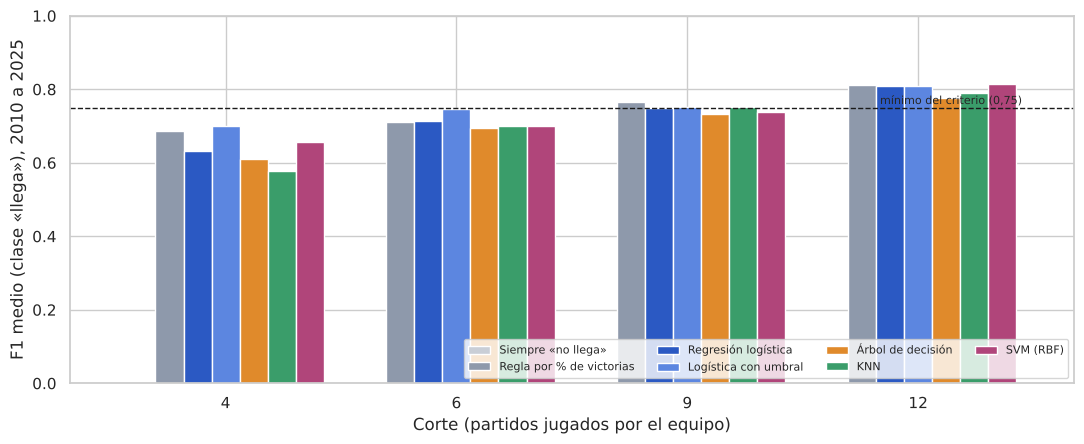

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.6))
piv = res.pivot(index="corte", columns="modelo", values="f1_medio")[orden]
piv.rename(columns=NOMBRES).plot(kind="bar", ax=ax, width=.85, color=["#C9CED6", "#8E99AB", "#2B59C3", "#5C86E0", "#E08A2B", "#3A9D6A", "#B0457A"])
ax.axhline(CRITERIO["f1_medio_min"], color="k", ls="--", lw=1); ax.text(3.45, CRITERIO["f1_medio_min"] + .01, "mínimo del criterio (0,75)", ha="right", fontsize=8)
ax.set_xlabel("Corte (partidos jugados por el equipo)"); ax.set_ylabel("F1 medio (clase «llega»), 2010 a 2025"); ax.set_ylim(0, 1)
ax.legend(fontsize=8, ncol=4, loc="lower right"); plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(FIGURAS / "f1_medio_por_corte_y_modelo.png", dpi=150); plt.show()

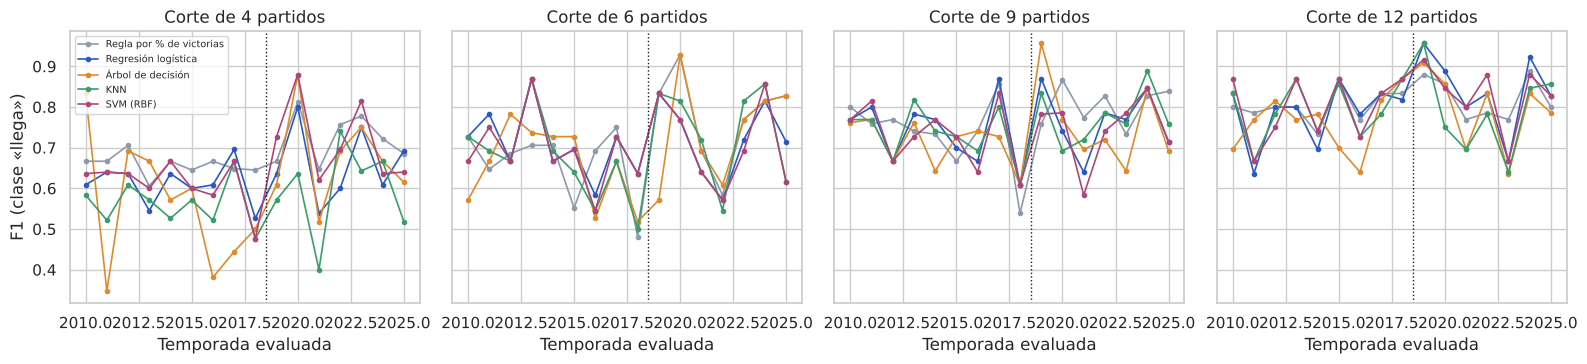

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, n in zip(axes, CORTES):
    for mod, col in [("regla_pct_victorias", "#8E99AB"), ("logistica", "#2B59C3"), ("arbol", "#E08A2B"), ("knn", "#3A9D6A"), ("svm", "#B0457A")]:
        d = met[(met.corte == n) & (met.modelo == mod)]
        ax.plot(d.season, d.f1, marker="o", ms=3, lw=1.2, color=col, label=NOMBRES[mod])
    ax.axvline(2018.5, color="k", ls=":", lw=1); ax.set_title(f"Corte de {n} partidos"); ax.set_xlabel("Temporada evaluada")
axes[0].set_ylabel("F1 (clase «llega»)"); axes[0].legend(fontsize=7); plt.tight_layout()
plt.savefig(FIGURAS / "f1_por_temporada.png", dpi=150); plt.show()

La línea punteada separa las temporadas 2010 a 2018 (nunca usadas como prueba) de 2019 a 2025 (ya vistas en la Semana 6). Un resultado en el segundo grupo no se tomaría como prueba completamente nueva.

## 5. Criterio de «predicción confiable»

In [9]:
crit = aplicar_criterio(met, res)
crit.to_csv(REPORTES / "criterio_por_corte_y_modelo.csv", index=False)
c = crit.copy(); c["modelo"] = c.modelo.map(NOMBRES)
c.set_index(["corte", "modelo"]).round(3)

f1_medio  f1_regla  mejora_vs_regla  temporadas_mejor_que_regla  cumple_f1_medio  cumple_mejora_sobre_regla  cumple_temporadas_mejor  \
corte modelo                                                                                                                                                       
4     Árbol de decisión        0.611     0.687           -0.076                           3            False                      False                    False   
      KNN                      0.577     0.687           -0.110                           1            False                      False                    False   
      Regresión logística      0.633     0.687           -0.054                           2            False                      False                    False   
      Logística con umbral     0.701     0.687            0.015                          10            False                      False                    False   
      SVM (RBF)                0.658     0.687           -0.029                           4            False                      False                    False   
6     Árbol de decisión        0.696     0.712           -0.016                           7            False                      False                    False   
      KNN                      0.700     0.712           -0.012                           7            False                      False                    False   
      Regresión logística      0.714     0.712            0.001                           4            False                      False                    False   
      Logística con umbral     0.748     0.712            0.035                          11            False                       True                     True   
      SVM (RBF)                0.700     0.712           -0.012                           5            False                      False                    False   
9     Árbol de decisión        0.733     0.764           -0.031                           6            False                      False                    False   
      KNN                      0.752     0.764           -0.013                           8             True                      False                    False   
      Regresión logística      0.750     0.764           -0.015                           9            False                      False                    False   
      Logística con umbral     0.752     0.764           -0.013                           5             True                      False                    False   
      SVM (RBF)                0.737     0.764           -0.027                           7            False                      False                    False   
12    Árbol de decisión        0.776     0.811           -0.035                           5             True                      False                    False   
      KNN                      0.791     0.811           -0.020                           6             True                      False                    False   
      Regresión logística      0.810     0.811           -0.001                           8             True                      False                    False   
      Logística con umbral     0.810     0.811           -0.001                           6             True                      False                    False   
      SVM (RBF)                0.813     0.811            0.002                           8             True                      False                    False   

                            cumple_precision  cumple_recall  cumple_desvio  cumple_todo  
corte modelo                                                                             
4     Árbol de decisión                False          False          False        False  
      KNN                              False          False           True        False  
      Regresión logística               True          False

In [10]:
cumplen = crit[crit.cumple_todo]
if len(cumplen):
    corte_final = int(cumplen.corte.min())
    modelo_final = cumplen[cumplen.corte == corte_final].sort_values("f1_medio", ascending=False).modelo.iloc[0]
    R["cumple"] = True
    texto = (f"El **primer corte, entre los cuatro evaluados, que cumpliría el criterio** sería el de **{corte_final} partidos**. "
             f"Entre los modelos que lo cumplen en ese corte, el de mayor F1 medio sería **{NOMBRES[modelo_final]}**.")
else:
    mejor = crit.sort_values("f1_medio", ascending=False).iloc[0]
    corte_final, modelo_final = int(mejor.corte), mejor.modelo
    R["cumple"] = False
    texto = (f"**Ningún corte cumpliría el criterio completo.** Para poder mostrar el uso del modelo se tomaría el de mayor F1 medio "
             f"({NOMBRES[modelo_final]}, corte de {corte_final} partidos), sin presentarlo como «confiable».")
R["corte_final"], R["modelo_final"] = corte_final, modelo_final
display(Markdown(texto))

**Ningún corte cumpliría el criterio completo.** Para poder mostrar el uso del modelo se tomaría el de mayor F1 medio (SVM (RBF), corte de 12 partidos), sin presentarlo como «confiable».

Esto no permitiría afirmar que se encontró el **número mínimo absoluto** de partidos, sino solo cuál sería el primer corte entre los cuatro evaluados (4, 6, 9 y 12) que cumpliría el criterio.

## 6. Matriz de confusión y métricas por clase del modelo final

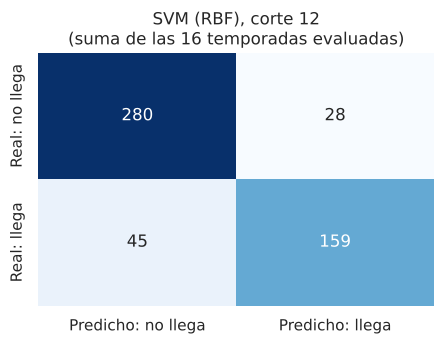

,precisión,recall,F1,casos reales
clase 0 (no llega),0.862,0.909,0.885,308
clase 1 (llega),0.850,0.779,0.813,204


In [11]:
d = met[(met.corte == corte_final) & (met.modelo == modelo_final)]
VP, FP, FN, VN = int(d.VP.sum()), int(d.FP.sum()), int(d.FN.sum()), int(d.VN.sum())
cm = pd.DataFrame([[VN, FP], [FN, VP]], index=["Real: no llega", "Real: llega"], columns=["Predicho: no llega", "Predicho: llega"])
plt.figure(figsize=(4.6, 3.6)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title(f"{NOMBRES[modelo_final]}, corte {corte_final}\n(suma de las 16 temporadas evaluadas)"); plt.tight_layout()
plt.savefig(FIGURAS / "matriz_confusion_modelo_final.png", dpi=150); plt.show()
def clase(vp, fp, fn):
    p = vp / (vp + fp) if vp + fp else 0; r = vp / (vp + fn) if vp + fn else 0
    return p, r, (2 * p * r / (p + r) if p + r else 0)
p1, r1, f1_1 = clase(VP, FP, FN); p0, r0, f1_0 = clase(VN, FN, FP)
por_clase = pd.DataFrame({"precisión": [p0, p1], "recall": [r0, r1], "F1": [f1_0, f1_1], "casos reales": [VN + FP, VP + FN]},
                         index=["clase 0 (no llega)", "clase 1 (llega)"]).round(3)
R.update(VP=VP, FP=FP, FN=FN, VN=VN, exactitud_global=(VP + VN) / (VP + FP + FN + VN))
por_clase

La matriz suma las 16 temporadas (512 equipos evaluados). Las métricas de la clase 1 («llega») serían las que se usan en el criterio. La exactitud global sería un dato complementario y no debería confundirse con la precisión.

## 7. Hiperparámetros elegidos y búsqueda

In [12]:
# Valor más elegido de cada hiperparámetro por corte y modelo, y cuántas veces (de 16 tramos)
hp2 = hp[~hp.modelo.isin(["regla_pct_victorias"])]
mas = hp2.groupby(["corte", "modelo"]).hiperparametros.agg(lambda s: f"{s.value_counts().index[0]}  ({s.value_counts().iloc[0]} de 16)")
mas.rename(index=NOMBRES, level=1).to_frame("configuración más elegida")

configuración más elegida
corte modelo                                                                 
4     Árbol de decisión     {'max_depth': 3, 'min_samples_leaf': 5}  (6 de...
      KNN                   {'m__n_neighbors': 35, 'm__weights': 'uniform'...
      Regresión logística                           {'m__C': 0.1}  (12 de 16)
      Logística con umbral              {'m__C': 0.1}, umbral=0.35  (9 de 16)
      SVM (RBF)                   {'m__C': 1, 'm__gamma': 'scale'}  (9 de 16)
6     Árbol de decisión     {'max_depth': 6, 'min_samples_leaf': 20}  (4 d...
      KNN                   {'m__n_neighbors': 51, 'm__weights': 'uniform'...
      Regresión logística                            {'m__C': 0.1}  (9 de 16)
      Logística con umbral              {'m__C': 0.1}, umbral=0.35  (6 de 16)
      SVM (RBF)                     {'m__C': 10, 'm__gamma': 0.01}  (5 de 16)
9     Árbol de decisión     {'max_depth': 4, 'min_samples_leaf': 20}  (4 d...
      KNN                   {'m__n_neighbors': 35, 'm__weights': 'uniform'...
      Regresión logística                              {'m__C': 1}  (6 de 16)
      Logística con umbral                {'m__C': 10}, umbral=0.6  (3 de 16)
      SVM (RBF)                     {'m__C': 10, 'm__gamma': 0.01}  (6 de 16)
12    Árbol de decisión     {'max_depth': 4, 'min_samples_leaf': 20}  (5 d...
      KNN                   {'m__n_neighbors': 51, 'm__weights': 'uniform'...
      Regresión logística                              {'m__C': 1}  (8 de 16)
      Logística con umbral                 {'m__C': 1}, umbral=0.5  (6 de 16)
      SVM (RBF)                    {'m__C': 10, 'm__gamma': 0.01}  (11 de 16)

In [13]:
# Búsqueda visible de un tramo concreto (se evalúa 2025: entrenamiento 2002-2024), para el modelo final
fam = "logistica" if modelo_final == "logistica_umbral" else modelo_final
años_tr, y = tramos_walk_forward()[-1]
tr = tablas[corte_final][tablas[corte_final].season.isin(años_tr)].reset_index(drop=True)
gs, _ = buscar(fam, tr, años_tr, PREDICTORES[corte_final])
cv = pd.DataFrame(gs.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score")
print(f"Tramo que evalúa {y}. Validación interna: las últimas 4 temporadas del entrenamiento, una por vez. Métrica: F1.")
cv.rename(columns={"mean_test_score": "F1 medio (validación)", "std_test_score": "desvío", "rank_test_score": "puesto"}).round(3).head(10)

Tramo que evalúa 2025. Validación interna: las últimas 4 temporadas del entrenamiento, una por vez. Métrica: F1.


,params,F1 medio (validación),desvío,puesto
8,"{'m__C': 10, 'm__gamma': 0.01}",0.807,0.087,1
7,"{'m__C': 10, 'm__gamma': 0.1}",0.800,0.057,2
4,"{'m__C': 1, 'm__gamma': 0.1}",0.787,0.071,3
5,"{'m__C': 1, 'm__gamma': 0.01}",0.782,0.076,4
6,"{'m__C': 10, 'm__gamma': 'scale'}",0.778,0.088,5
3,"{'m__C': 1, 'm__gamma': 'scale'}",0.774,0.066,6
1,"{'m__C': 0.1, 'm__gamma': 0.1}",0.762,0.056,7
0,"{'m__C': 0.1, 'm__gamma': 'scale'}",0.762,0.056,7
2,"{'m__C': 0.1, 'm__gamma': 0.01}",0.732,0.052,9


Las métricas de esta tabla corresponden a la **validación interna** y sirven para elegir los hiperparámetros. Las métricas del modelo serían las de la evaluación en la temporada reservada (secciones 4 a 6).

## 8. Efecto del umbral de decisión (regresión logística)

In [14]:
u = res[res.modelo.isin(["logistica", "logistica_umbral"])].copy()
u["modelo"] = u.modelo.map(NOMBRES)
umb = hp[(hp.modelo == "logistica_umbral") & (hp.corte == corte_final)].hiperparametros.str.extract(r"umbral=([0-9.]+)")[0].astype(float)
R["umbral_mediana"] = float(umb.median())
display(u.set_index(["corte", "modelo"])[["precision_media", "recall_medio", "f1_medio", "f1_desvio"]].round(3))
display(Markdown(f"Con umbral 0,5 la logística equilibraría precisión y recall. Al elegir el umbral con la validación interna (mediana de los 16 tramos en el corte de {corte_final}: **{R['umbral_mediana']:.2f}**), "
                 "bajar el umbral aumentaría el recall a costa de la precisión (más falsas alarmas). Solo se mantendría si mejora el F1 medio de forma estable."))

precision_media  recall_medio  f1_medio  f1_desvio
corte modelo                                                                  
4     Regresión logística             0.731         0.568     0.633      0.074
      Logística con umbral            0.644         0.778     0.701      0.103
6     Regresión logística             0.776         0.668     0.714      0.086
      Logística con umbral            0.712         0.795     0.748      0.086
9     Regresión logística             0.784         0.726     0.750      0.079
      Logística con umbral            0.743         0.769     0.752      0.074
12    Regresión logística             0.856         0.775     0.810      0.086
      Logística con umbral            0.849         0.781     0.810      0.074

Con umbral 0,5 la logística equilibraría precisión y recall. Al elegir el umbral con la validación interna (mediana de los 16 tramos en el corte de 12: **0.50**), bajar el umbral aumentaría el recall a costa de la precisión (más falsas alarmas). Solo se mantendría si mejora el F1 medio de forma estable.

## 9. Modelo final y cómo predice

In [15]:
t_final = tablas[corte_final]
final = ajustar_final(modelo_final, t_final, corte_final)
joblib.dump(final, MODELOS_DIR / "modelo_final.joblib")
R["hiperparametros_final"] = str(final["hiperparametros"]) + (f", umbral={final['umbral']}" if final["umbral"] is not None else "")
print("Modelo final:", NOMBRES[modelo_final], "| corte", corte_final, "| entrenado con 2002-2025 |", R["hiperparametros_final"])
print("Guardado en models/modelo_final.joblib")

Modelo final: SVM (RBF) | corte 12 | entrenado con 2002-2025 | {'m__C': 10, 'm__gamma': 0.01}
Guardado en models/modelo_final.joblib


In [16]:
# Caso concreto para explicar a los tres modelos (un equipo inventado después del partido N)
N = corte_final
caso = pd.DataFrame([{"pct_victorias": 0.667, "puntos_favor_prom": 26.0, "puntos_contra_prom": 21.0, "partidos_local": N // 2, "pct_victorias_ult4": 0.75}])
caso = caso[PREDICTORES[N]]
fit = {k: ajustar_final(k, t_final, N) for k in ["logistica", "knn", "arbol"]}
display(caso.round(3))

,pct_victorias,puntos_favor_prom,puntos_contra_prom,partidos_local,pct_victorias_ult4
0,0.667,26.0,21.0,6,0.75


In [17]:
# Regresión logística: z = intercepto + suma(peso x valor escalado); probabilidad = sigmoide(z); clase según el umbral
lg = fit["logistica"]["pipeline"]; esc, m = lg.named_steps["esc"], lg.named_steps["m"]
zs = esc.transform(caso)[0]
aporte = pd.DataFrame({"valor": caso.iloc[0].values, "valor escalado": zs, "peso": m.coef_[0], "aporte": zs * m.coef_[0]}, index=caso.columns)
z = m.intercept_[0] + aporte.aporte.sum(); prob = 1 / (1 + np.exp(-z))
display(aporte.round(3))
display(Markdown(f"Intercepto = {m.intercept_[0]:.3f}. **z** = {z:.3f}, probabilidad = 1 / (1 + e^(-z)) = **{prob:.3f}**. Con umbral 0,5, la clase sería **{int(prob >= 0.5)}** ({'llega' if prob >= 0.5 else 'no llega'})."))

,valor,valor escalado,peso,aporte
pct_victorias,0.667,0.813,2.591,2.107
puntos_favor_prom,26.000,0.804,0.456,0.367
puntos_contra_prom,21.000,-0.345,-0.354,0.122
partidos_local,6.000,-0.002,-0.107,0.000
pct_victorias_ult4,0.750,0.847,-0.036,-0.031


Intercepto = -1.038. **z** = 1.527, probabilidad = 1 / (1 + e^(-z)) = **0.822**. Con umbral 0,5, la clase sería **1** (llega).

In [18]:
# KNN: los k vecinos más parecidos (en variables escaladas) votan
kn = fit["knn"]["pipeline"]; esc, m = kn.named_steps["esc"], kn.named_steps["m"]
X = t_final[PREDICTORES[N]]
dist, idx = m.kneighbors(esc.transform(caso), n_neighbors=5)
vec = t_final.iloc[idx[0]][["season", "team", "pct_victorias", "puntos_favor_prom", "puntos_contra_prom", OBJETIVO]].copy()
vec["distancia"] = dist[0]
display(vec.round(3))
display(Markdown(f"Se muestran los 5 vecinos más cercanos como ilustración. El modelo elegido usa **k = {m.n_neighbors}** ({m.weights}). "
                 f"Predicción del modelo para este caso: **clase {int(kn.predict(caso)[0])}**. Sin escalar, `puntos_favor_prom` (valores de 10 a 35) pesaría mucho más que `partidos_local` en la distancia."))

,season,team,pct_victorias,puntos_favor_prom,puntos_contra_prom,llega_playoffs,distancia
111,2005,KC,0.667,25.083,21.417,0,0.228
200,2008,DAL,0.667,24.917,21.667,0,0.294
331,2012,GB,0.667,24.667,21.583,1,0.328
193,2008,ATL,0.667,24.833,20.167,1,0.336
750,2025,JAX,0.667,24.333,21.083,1,0.363


Se muestran los 5 vecinos más cercanos como ilustración. El modelo elegido usa **k = 5** (distance). Predicción del modelo para este caso: **clase 1**. Sin escalar, `puntos_favor_prom` (valores de 10 a 35) pesaría mucho más que `partidos_local` en la distancia.

In [19]:
# Árbol: recorrido del caso por las preguntas hasta la hoja
ar = fit["arbol"]["pipeline"]
nodos = ar.decision_path(caso).indices; hoja = ar.apply(caso)[0]
print("Recorrido del caso:")
for nodo in nodos:
    if nodo == hoja:
        v = ar.tree_.value[nodo][0] * ar.tree_.n_node_samples[nodo]; print(f"  hoja {nodo}: clase {int(np.argmax(v))}  (en el entrenamiento, no llega: {v[0]:.0f} equipos, llega: {v[1]:.0f} equipos)"); continue
    f = PREDICTORES[N][ar.tree_.feature[nodo]]; th = ar.tree_.threshold[nodo]; val = caso.iloc[0][f]
    print(f"  ¿{f} <= {th:.3f}?  valor del caso = {val:.3f}  ->  {'sí' if val <= th else 'no'}")
print("\nÁrbol completo (profundidad", ar.get_depth(), "):"); print(export_text(ar, feature_names=PREDICTORES[N]))

Recorrido del caso:
  ¿pct_victorias <= 0.604?  valor del caso = 0.667  ->  no
  ¿pct_victorias <= 0.688?  valor del caso = 0.667  ->  sí
  ¿puntos_favor_prom <= 23.167?  valor del caso = 26.000  ->  no
  ¿pct_victorias_ult4 <= 0.562?  valor del caso = 0.750  ->  no
  hoja 21: clase 1  (en el entrenamiento, no llega: 7 equipos, llega: 29 equipos)

Árbol completo (profundidad 4 ):
|--- pct_victorias <= 0.60
|   |--- pct_victorias <= 0.44
|   |   |--- puntos_contra_prom <= 23.88
|   |   |   |--- puntos_favor_prom <= 21.38
|   |   |   |   |--- class: 0
|   |   |   |--- puntos_favor_prom >  21.38
|   |   |   |   |--- class: 0
|   |   |--- puntos_contra_prom >  23.88
|   |   |   |--- puntos_contra_prom <= 27.54
|   |   |   |   |--- class: 0
|   |   |   |--- puntos_contra_prom >  27.54
|   |   |   |   |--- class: 0
|   |--- pct_victorias >  0.44
|   |   |--- pct_victorias <= 0.56
|   |   |   |--- pct_victorias_ult4 <= 0.44
|   |   |   |   |--- class: 0
|   |   |   |--- pct_victorias_ult4 >  

## 10. Uso del modelo con casos nuevos

**a) Casos sintéticos (inventados).** Se pasarían por el modelo final ya ajustado (`predecir`). Sobre estos casos **no se calcularían métricas**, ya que solo mostrarían cómo se usa el modelo.

In [20]:
sint = pd.DataFrame([
    {"caso": "Equipo A (muy buen arranque)", "pct_victorias": 0.78, "puntos_favor_prom": 28.0, "puntos_contra_prom": 18.0, "partidos_local": 5, "pct_victorias_ult4": 0.75},
    {"caso": "Equipo B (arranque parejo)", "pct_victorias": 0.50, "puntos_favor_prom": 22.0, "puntos_contra_prom": 22.0, "partidos_local": 4, "pct_victorias_ult4": 0.50},
    {"caso": "Equipo C (mal arranque)", "pct_victorias": 0.22, "puntos_favor_prom": 16.0, "puntos_contra_prom": 27.0, "partidos_local": 5, "pct_victorias_ult4": 0.25},
]).set_index("caso")
out = predecir(final, sint)
sint[PREDICTORES[N]].join(out).round(3)

,pct_victorias,puntos_favor_prom,puntos_contra_prom,partidos_local,pct_victorias_ult4,prob_llega,prediccion
caso,,,,,,,
Equipo A (muy buen arranque),0.78,28.0,18.0,5,0.75,NaN,1
Equipo B (arranque parejo),0.50,22.0,22.0,4,0.50,NaN,1
Equipo C (mal arranque),0.22,16.0,27.0,5,0.25,NaN,0


**b) Casos reales de la temporada 2026 (en curso).** El archivo crudo incluye partidos de 2026 ya jugados al momento de la descarga (2 de noviembre de 2026). Como en esa fecha los equipos tenían entre 7 y 8 partidos jugados, el corte más avanzado disponible sería el de **6 partidos**: se calcularían las variables de cada equipo **después de su partido 6** con el mismo código y se aplicaría el modelo con mayor F1 medio en ese corte. Es una **ilustración**: la temporada todavía no terminó, por lo que no hay etiqueta real y **no se calcularían métricas**.

In [21]:
g26 = cargar_partidos(RAW / "games.csv", temporada_max=2026)
g26 = g26[g26.season == 2026]
tg26 = partidos_por_equipo(g26)
jugados = tg26.groupby("team").n_partido.max()
N26 = max(c for c in CORTES if (jugados >= c).sum() >= 16)          # corte más avanzado que ya alcanzaron la mayoría de los equipos
mod26 = res[(res.corte == N26) & res.modelo.isin(["logistica", "logistica_umbral", "arbol", "knn", "svm"])].sort_values("f1_medio", ascending=False).modelo.iloc[0]
final26 = ajustar_final(mod26, tablas[N26], N26)
joblib.dump(final26, MODELOS_DIR / "modelo_2026_ilustrativo.joblib")
R["corte_2026"], R["modelo_2026"] = int(N26), mod26
v26 = variables_corte(tg26, N26)
v26 = v26[v26.partidos == N26].copy()
v26 = v26.set_index("team").sort_index()
pr = predecir(final26, v26)
tabla26 = v26[["victorias", "empates", "derrotas"] + PREDICTORES[N26]].join(pr).sort_values("prob_llega", ascending=False)
tabla26["prediccion"] = tabla26.prediccion.map({1: "llega", 0: "no llega"})
R["n_equipos_2026"] = int(len(tabla26)); R["n_llega_2026"] = int((tabla26.prediccion == "llega").sum())
print(f"Corte {N26} partidos, modelo {NOMBRES[mod26]}. Equipos de 2026 con al menos {N26} partidos jugados en los datos descargados: {len(tabla26)}")
tabla26.round(3)

Corte 6 partidos, modelo Logística con umbral. Equipos de 2026 con al menos 6 partidos jugados en los datos descargados: 32


,victorias,empates,derrotas,pct_victorias,puntos_favor_prom,puntos_contra_prom,partidos_local,pct_victorias_ult4,prob_llega,prediccion
team,,,,,,,,,,
SF,6,0,0,1.000,29.500,18.333,4,1.000,0.918,llega
MIN,6,0,0,1.000,20.833,12.333,3,1.000,0.916,llega
KC,5,0,1,0.833,23.833,17.167,3,0.750,0.807,llega
BUF,5,0,1,0.833,32.833,28.500,3,0.750,0.786,llega
CIN,4,0,2,0.667,27.167,20.333,2,0.500,0.739,llega
BAL,4,0,2,0.667,26.000,22.000,2,0.750,0.710,llega
CHI,4,0,2,0.667,25.000,19.833,3,0.750,0.655,llega
JAX,4,0,2,0.667,25.667,17.333,4,0.750,0.649,llega
DET,4,0,2,0.667,30.667,27.500,3,0.750,0.624,llega


## 11. Variables que más pesan (interpretación)

In [22]:
lg = fit["logistica"]["pipeline"]
coef = pd.Series(lg.named_steps["m"].coef_[0], index=PREDICTORES[N]).sort_values(key=abs, ascending=False)
imp = pd.Series(fit["arbol"]["pipeline"].feature_importances_, index=PREDICTORES[N]).sort_values(ascending=False)
display(pd.DataFrame({"peso en la logística (variables escaladas)": coef, "importancia en el árbol": imp}).round(3))

,peso en la logística (variables escaladas),importancia en el árbol
partidos_local,-0.107,0.000
pct_victorias,2.591,0.960
pct_victorias_ult4,-0.036,0.007
puntos_contra_prom,-0.354,0.004
puntos_favor_prom,0.456,0.030


Estos pesos describirían **asociaciones** dentro de los datos de entrenamiento y no causas. Como `pct_victorias`, los puntos a favor y los puntos en contra estarían relacionados entre sí, el peso de cada una por separado se interpretaría con cautela.

## 12. Conclusiones

In [23]:
sub = res.set_index(["corte", "modelo"])
def f(c, m, col="f1_medio"): return sub.loc[(c, m), col]
base = {c: f(c, "regla_pct_victorias") for c in CORTES}
mejor_modelo = {c: res[(res.corte == c) & res.modelo.isin(["logistica", "logistica_umbral", "arbol", "knn", "svm"])].sort_values("f1_medio", ascending=False).iloc[0] for c in CORTES}
R["f1_por_corte"] = {int(c): {"regla": float(base[c]), "mejor_modelo": mejor_modelo[c].modelo, "mejor_f1": float(mejor_modelo[c].f1_medio),
                              "precision": float(mejor_modelo[c].precision_media), "recall": float(mejor_modelo[c].recall_medio),
                              "desvio_f1": float(mejor_modelo[c].f1_desvio)} for c in CORTES}
R["f1_modelo_final"] = float(f(corte_final, modelo_final)); R["precision_final"] = float(f(corte_final, modelo_final, "precision_media"))
R["recall_final"] = float(f(corte_final, modelo_final, "recall_medio")); R["desvio_final"] = float(f(corte_final, modelo_final, "f1_desvio"))
R["f1_final_2010_2018"] = float(f(corte_final, modelo_final, "f1_2010_2018")); R["f1_final_2019_2025"] = float(f(corte_final, modelo_final, "f1_2019_2025"))
R["f1_regla_final"] = float(base[corte_final])
lineas = ["| Corte | F1 regla % victorias | Mejor modelo | F1 medio | Precisión | Recall | Desvío del F1 |", "|---|---|---|---|---|---|---|"]
for c in CORTES:
    d = R["f1_por_corte"][int(c)]
    lineas.append(f"| {c} | {d['regla']:.3f} | {NOMBRES[d['mejor_modelo']]} | {d['mejor_f1']:.3f} | {d['precision']:.3f} | {d['recall']:.3f} | {d['desvio_f1']:.3f} |")
R["tabla_md"] = "\n".join(lineas)
display(Markdown(R["tabla_md"]))
sobre = [c for c in CORTES if R["f1_por_corte"][int(c)]["mejor_f1"] - R["f1_por_corte"][int(c)]["regla"] >= CRITERIO["mejora_min_sobre_regla"]]
R["cortes_con_mejora"] = [int(c) for c in sobre]
json.dump(R, open(REPORTES / "resultados.json", "w"), ensure_ascii=False, indent=1, default=str)

| Corte | F1 regla % victorias | Mejor modelo | F1 medio | Precisión | Recall | Desvío del F1 |
|---|---|---|---|---|---|---|
| 4 | 0.687 | Logística con umbral | 0.701 | 0.644 | 0.778 | 0.103 |
| 6 | 0.712 | Logística con umbral | 0.748 | 0.712 | 0.795 | 0.086 |
| 9 | 0.764 | Logística con umbral | 0.752 | 0.743 | 0.769 | 0.074 |
| 12 | 0.811 | SVM (RBF) | 0.813 | 0.856 | 0.781 | 0.079 |

In [24]:
HIP1 = ("La regla simple por % de victorias sería una referencia difícil de superar en estos datos, y podría deberse a que casi toda la información útil de las variables ya estaría resumida en el récord del equipo."
        if not R["cortes_con_mejora"] else
        "La mejora sobre la regla por % de victorias aparecería solo en el corte indicado y con la variante de logística con umbral, por lo que podría deberse al ajuste del umbral más que al tipo de modelo; con 16 temporadas no alcanzaría para afirmarlo.")
txt = f"""**Resultados (con los datos y la evaluación descriptos)**
- El modelo final sería **{NOMBRES[modelo_final]}** con el corte de **{corte_final} partidos**: F1 medio {R['f1_modelo_final']:.3f}, precisión media {R['precision_final']:.3f}, recall medio {R['recall_final']:.3f} y desvío del F1 entre temporadas {R['desvio_final']:.3f}. La regla por % de victorias obtendría {R['f1_regla_final']:.3f} en ese corte.
- {'El criterio de confiabilidad se cumpliría en ese corte.' if R['cumple'] else 'El criterio de confiabilidad no se cumpliría completo en ningún corte; los valores se informan tal cual.'}
- En 2010 a 2018 el F1 medio del modelo final sería {R['f1_final_2010_2018']:.3f} y en 2019 a 2025 (ya vistas) {R['f1_final_2019_2025']:.3f}.
- Cortes en que el mejor modelo superaría a la regla en al menos {CRITERIO['mejora_min_sobre_regla']} de F1: {', '.join(map(str, R['cortes_con_mejora'])) or 'ninguno'}.

**Hipótesis (no verificadas)**
- {HIP1}
- Una parte de la mejora entre cortes podría deberse a que, con más partidos jugados, el récord se parecería más al resultado final de la temporada.

**Limitaciones**
- Evaluación retrospectiva, con 16 temporadas (512 equipos por corte) y los cuatro cortes correlacionados entre sí.
- Las temporadas 2019 a 2025 ya se habían usado como prueba y la exploración usó todas las temporadas.
- Las variables solo salen de resultados de partidos (sin lesiones, mariscal de campo ni calendario restante).
- La predicción en un tramo no probaría que la regla elegida funcione en el futuro, y las asociaciones no serían causas."""
display(Markdown(txt))
open(REPORTES / "resultados.md", "w", encoding="utf-8").write("# Resultados (generado por el notebook 2.0)\n\n" + R["tabla_md"] + "\n\n" + txt + "\n")

**Resultados (con los datos y la evaluación descriptos)**
- El modelo final sería **SVM (RBF)** con el corte de **12 partidos**: F1 medio 0.813, precisión media 0.856, recall medio 0.781 y desvío del F1 entre temporadas 0.079. La regla por % de victorias obtendría 0.811 en ese corte.
- El criterio de confiabilidad no se cumpliría completo en ningún corte; los valores se informan tal cual.
- En 2010 a 2018 el F1 medio del modelo final sería 0.800 y en 2019 a 2025 (ya vistas) 0.831.
- Cortes en que el mejor modelo superaría a la regla en al menos 0.03 de F1: 6.

**Hipótesis (no verificadas)**
- La mejora sobre la regla por % de victorias aparecería solo en el corte indicado y con la variante de logística con umbral, por lo que podría deberse al ajuste del umbral más que al tipo de modelo; con 16 temporadas no alcanzaría para afirmarlo.
- Una parte de la mejora entre cortes podría deberse a que, con más partidos jugados, el récord se parecería más al resultado final de la temporada.

**Limitaciones**
- Evaluación retrospectiva, con 16 temporadas (512 equipos por corte) y los cuatro cortes correlacionados entre sí.
- Las temporadas 2019 a 2025 ya se habían usado como prueba y la exploración usó todas las temporadas.
- Las variables solo salen de resultados de partidos (sin lesiones, mariscal de campo ni calendario restante).
- La predicción en un tramo no probaría que la regla elegida funcione en el futuro, y las asociaciones no serían causas.

1902